# Spectral Pact (Harakim)

Spectral Pact is a 180 s self buff. Every hit the caster takes is mitigated by the caster's own
armor first. Then 30–75% of the post-armor damage is moved, split evenly, onto the caster's
living ghost companions. Their armor and shields do not apply to the share, so the caster takes
exactly `100 − redirect` percent of what they would have lost.

**Rebalanced.** The pact used to split the **raw** damage before armor. Each share then went
through the companion's own armor, and the caster's armor applied in full to the smaller
remainder. At the cap that made the caster immune to any hit up to about 4 × their armor, and the
second armor pass deleted part of the redirected damage. The split now happens after the
caster's armor (`apply_spectral_pact_redirect` in `do_hurt`), so the advertised percentage is
exact. The curve was also spread from `30 + 45p/100` (cap at 100) to `30 + 45p/150` (cap at 150).
The "before" curves below show the old behaviour.

| | |
|---|---|
| Class | Harakim |
| Target | Self (redirects to owned ghost companions) |
| Cost | 20 mana (not divided by 3 for Harakim) |
| Cooldown | none, but it cannot be recast while active (no refresh) |
| Landing roll | none |
| Duration | 180 s, or until no companion is left |
| Effect | `redirect = clamp(30 + ⌊45p/150⌋, 30, 75)` % of the caster's post-armor damage in every `do_hurt` (not self-inflicted damage) |
| Source | `server/src/driver/skill/companion.rs::skill_spectral_pact`; redirect in `server/src/state/stats.rs::apply_spectral_pact_redirect`, called from `do_hurt` after `mitigate_hurt` |

---

# Formula

With $p$ the modified skill, $r$ the redirect percent, $n$ living companions, $d$ the raw damage
passed to `do_hurt` and $A$ the caster's armor:

$$
r = \operatorname{clamp}\!\left(30 + \left\lfloor \tfrac{45p}{150} \right\rfloor,\ 30,\ 75\right)
\qquad
D = 1000\,k\cdot\max(0,\ d - A)
\qquad
s = \left\lfloor \frac{\lfloor D\,r/100 \rfloor}{n} \right\rfloor
$$

$$
\text{owner milli-HP} = D - n s
\qquad
\text{each companion milli-HP} = s
$$

with $k = 0.25$ for melee (type 0) and $0.75$ for spells (types 1/2). $D$ is what the caster
would lose without the pact, in thousandths of HP. The split happens **after** armor and the
share skips the companion's armor and Magic Shield. The caster and companions together lose
exactly $D$, and the caster keeps $(100 - r)\%$ of it whatever the armor or hit size.

| Quantity | Breakpoint |
|---|---|
| Ceiling | 75% from $p \ge 150$ (before: from $p \ge 100$) |
| Floor | 30% for $p \le 4$ |
| Slope | +3% per 10 skill points (before: +4.5%) |
| At the raise cap ($p$ 105) | 61% (before: 75%) |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
MANA_COST = 20
DURATION_S = 180

# Model

In [2]:
def redirect_pct(p):
    return mm.clamp(30 + mm.idiv(np.asarray(p) * 45, 150), 30, 75)


def post_armor_milli(dam, armor, kind=0):
    """`mitigate_hurt`: the caster's post-armor damage in thousandths of HP."""
    return np.rint(np.asarray(mm.hurt_hp(dam, armor, kind)) * 1000).astype(np.int64)


def split(dam, r, owner_armor=0, n=1, kind=0):
    """(milli-HP left on the owner, milli-HP per companion) for one `do_hurt`."""
    post = post_armor_milli(dam, owner_armor, kind)
    share = (post * r // 100) // n
    return post - n * share, share


def owner_hp(dam, r, owner_armor, n=1, kind=0):
    return split(dam, r, owner_armor, n, kind)[0] / 1000


def melee_owner_ratio(p, owner_armor, wv=60, strength=80, n=1):
    """Expected owner HP per landed melee hit with the pact / without it."""
    rolls = mm.melee_raw_rolls(wv, strength)
    base = np.mean(mm.hurt_hp(rolls, owner_armor))
    r = np.atleast_1d(redirect_pct(p))
    with_pact = np.array([np.mean(owner_hp(rolls, x, owner_armor, n)) for x in r])
    return with_pact / base if base > 0 else np.full(r.shape, np.nan)


def melee_companion_hp(p, owner_armor, wv=60, strength=80, n=1):
    """Expected HP each companion loses per landed melee hit on the owner (its own armor is skipped)."""
    rolls = mm.melee_raw_rolls(wv, strength)
    return np.array([np.mean(split(rolls, x, owner_armor, n)[1]) / 1000
                     for x in np.atleast_1d(redirect_pct(p))])


# Before the rebalance: raw damage split before armor, both armors applied, cap at skill 100.
def old_redirect_pct(p):
    return mm.clamp(30 + mm.idiv(np.asarray(p) * 45, 100), 30, 75)


def old_split(dam, r, n=1):
    """(raw damage left on the owner, raw share per companion) for one `do_hurt`."""
    dam = np.asarray(dam)
    share = (dam * r // 100) // n
    return np.maximum(0, dam - n * share), share


def old_owner_hp(dam, r, owner_armor, n=1, kind=0):
    left, _ = old_split(dam, r, n)
    return mm.hurt_hp(left, owner_armor, kind)


def old_melee_owner_ratio(p, owner_armor, wv=60, strength=80, n=1):
    rolls = mm.melee_raw_rolls(wv, strength)
    base = np.mean(mm.hurt_hp(rolls, owner_armor))
    r = np.atleast_1d(old_redirect_pct(p))
    with_pact = np.array([np.mean(old_owner_hp(rolls, x, owner_armor, n)) for x in r])
    return with_pact / base if base > 0 else np.full(r.shape, np.nan)


def old_melee_companion_hp(p, comp_armor, wv=60, strength=80, n=1):
    rolls = mm.melee_raw_rolls(wv, strength)
    return np.array([np.mean(mm.hurt_hp(old_split(rolls, x, n)[1], comp_armor))
                     for x in np.atleast_1d(old_redirect_pct(p))])

# Validation

- `spectral_pact_sets_redirect_percent_and_cannot_stack`: skill 50 → 45%, the item lasts
  `TICKS*180`, mana 50,000 → 30,000; a second cast is refused and spends nothing.
- `spectral_pact_redirect_is_capped_below_full_damage`: skill 100 → 60%, 149 → 74%, 150 and
  250 → 75%.
- `spectral_pact_redirects_share_of_post_armor_damage`: melee 100 raw against owner armor 20 is
  20,000 milli-HP; at 75% the owner loses 5,000 and the armor-30 companion 15,000.
- `spectral_pact_splits_share_evenly_between_two_companions`: the same hit leaves 5,000 on the
  owner and 7,500 on each companion.
- `spectral_pact_redirects_nothing_from_a_fully_armored_hit`: raw 20 against armor 20 moves
  nothing.
- `spectral_pact_without_companions_leaves_damage_on_owner`: the owner takes the full 20,000.

In [3]:
assert redirect_pct(50) == 45 and redirect_pct(250) == 75 and redirect_pct(0) == 30
assert [int(redirect_pct(p)) for p in (100, 105, 149, 150)] == [60, 61, 74, 75]
assert 50_000 - MANA_COST * 1000 == 30_000 and mm.TICKS * DURATION_S == 6480
assert split(100, 75, owner_armor=20) == (5_000, 15_000)
assert split(100, 75, owner_armor=20, n=2) == (5_000, 7_500)
assert split(20, 75, owner_armor=20) == (0, 0)
assert old_redirect_pct(50) == 52 and old_redirect_pct(100) == 75
assert old_split(100, 75) == (25, 75) and old_split(100, 75, 2) == (26, 37)
print("Spectral Pact model OK")

Spectral Pact model OK


# Plots

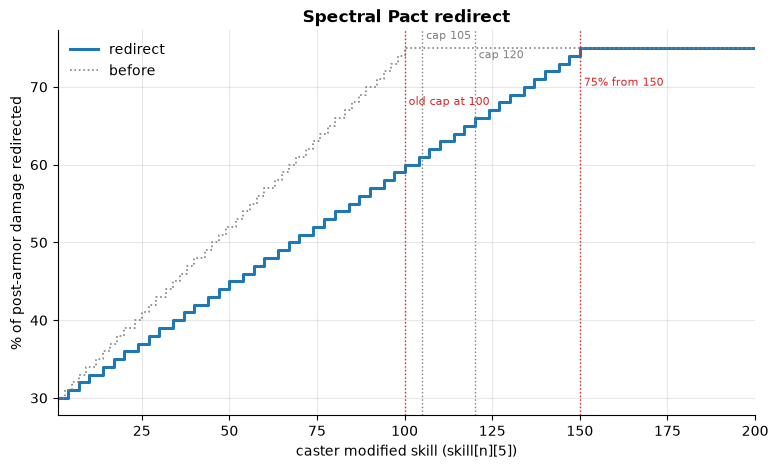

In [4]:
fig, ax = plt.subplots()
ax.step(P, redirect_pct(P), where="post", lw=2.2, label="redirect")
ax.step(P, old_redirect_pct(P), where="post", color="grey", lw=1.2, ls=":", label="before")
mm.skill_axis(ax, "% of post-armor damage redirected", "Spectral Pact redirect")
mm.mark_caps(ax, extra=[(150, "75% from 150"), (100, "old cap at 100")])
ax.legend()

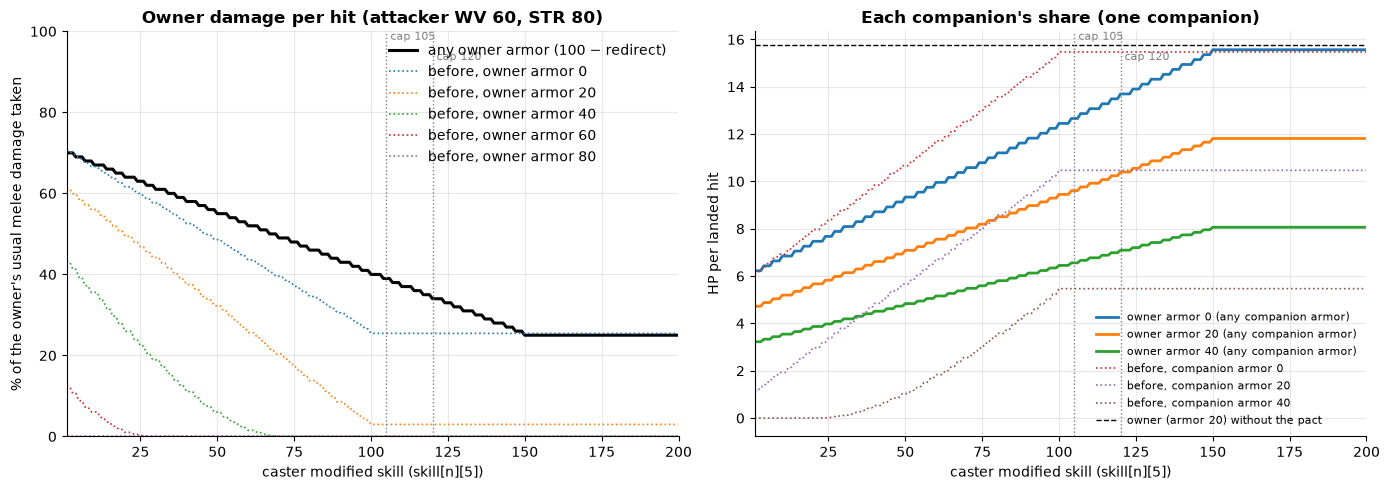

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(P, 100 * melee_owner_ratio(P, 20), color="black", lw=2.2, label="any owner armor (100 − redirect)")
for armor in mm.ARMOR_SWEEP:
    ax.plot(P, 100 * old_melee_owner_ratio(P, armor), lw=1.2, ls=":", label=f"before, owner armor {armor}")
mm.skill_axis(ax, "% of the owner's usual melee damage taken", "Owner damage per hit (attacker WV 60, STR 80)")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for owner_armor in (0, 20, 40):
    line, = ax.plot(P, melee_companion_hp(P, owner_armor), label=f"owner armor {owner_armor} (any companion armor)")
for comp_armor in (0, 20, 40):
    ax.plot(P, old_melee_companion_hp(P, comp_armor), lw=1.2, ls=":", label=f"before, companion armor {comp_armor}")
ax.axhline(np.mean(mm.hurt_hp(mm.melee_raw_rolls(60, 80), 20)), color="black", ls="--", lw=1,
           label="owner (armor 20) without the pact")
mm.skill_axis(ax, "HP per landed hit", "Each companion's share (one companion)")
mm.mark_caps(ax)
ax.legend(fontsize=8)
plt.tight_layout()

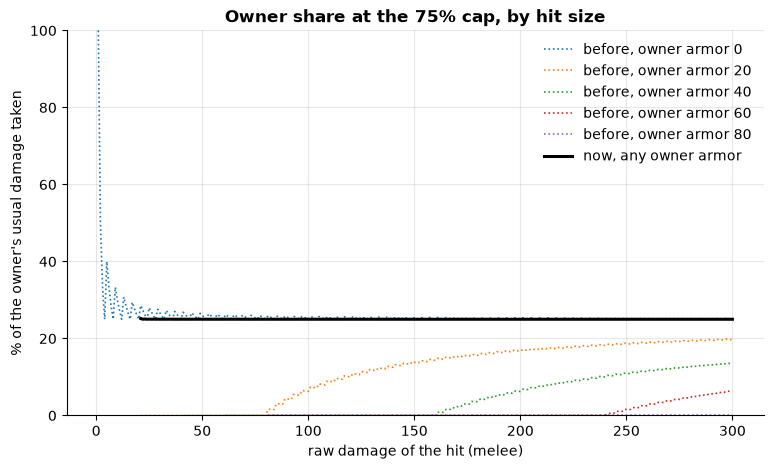

In [6]:
fig, ax = plt.subplots()
D = np.arange(1, 301)
for armor in mm.ARMOR_SWEEP:
    base = mm.hurt_hp(D, armor)
    old = old_owner_hp(D, 75, armor)
    ax.plot(D, 100 * np.where(base > 0, old / np.maximum(base, 1e-9), np.nan), lw=1.2, ls=":",
            label=f"before, owner armor {armor}")
new = owner_hp(D, 75, 20)
base = mm.hurt_hp(D, 20)
ax.plot(D, 100 * np.where(base > 0, new / np.maximum(base, 1e-9), np.nan), color="black", lw=2.2,
        label="now, any owner armor")
ax.set_xlabel("raw damage of the hit (melee)")
ax.set_ylabel("% of the owner's usual damage taken")
ax.set_title("Owner share at the 75% cap, by hit size")
ax.set_ylim(0, 100)
ax.legend()

# Observations

- **The percentage is now exact.** The owner keeps `100 − redirect` percent of their usual
  post-armor damage regardless of armor or hit size. Before, an armor-20 owner at the cap took
  only 3% of their usual melee damage from a WV 60, STR 80 attacker, and an armor-40 owner took
  nothing. Every raw hit up to about 4 × the owner's armor was ignored. Now the armor-20 owner
  takes 3.9 of 15.75 HP per hit at the cap (25%).
- **No damage leaves the system.** The owner and companions together lose exactly what the owner
  would have lost alone. Before, the companion's armor also applied to its share (−31% total at
  companion armor 20, −65% at 40). The share now skips the companion's armor and Magic Shield,
  so a tanky companion no longer helps. The owner's own Magic Shield and armor wear see the full
  hit, as they would without the pact.
- **Slower curve, cap at 150.** At the raise cap of 105 the pact redirects 61% (before: 75%), and
  the last 15 points come from gear and buffs. The owner takes 6.1 HP of 15.75 per hit at
  skill 105.
- **The companion is still the limit, and it drains faster.** Because its armor no longer
  applies, a companion absorbs 9.6 HP per hit at skill 105 (11.8 at the cap) in the example
  above. A Ghost 105 companion with about 190 HP lasts about 20 hits (16 at the cap). With Revenant
  Conduit at its cap (about 475 HP) it lasts about 49 hits (40 at the cap). When the last
  companion dies the pact is removed, and a new summon costs 45 mana plus a 20 mana recast.
- **Two companions split the share evenly.** With Kindred Spirit each companion takes half the
  share, so the pair lasts twice as long. Armor no longer changes the total.
- **Only `do_hurt` is redirected.** DoT ticks that write `a_hp` directly, such as the Lava Blast
  burn, bypass the pact. The split is in thousandths of HP, so only a hit that armor fully
  absorbs redirects nothing.
- **No refresh.** A recast is refused while the pact is up, so there is a short gap every 180 s
  (20 mana per 3 minutes).